# ML — Perfiles de carrera y detección de anomalías

Modelo **no supervisado** sobre `gold_derby_race_dynamics`:

1. **Clustering (KMeans):** agrupa a cada caballo-carrera según la **forma** de su perfil de
   velocidad, para identificar estilos de carrera (puntero, cerrador, ritmo parejo…).
2. **Detección de anomalías:** la distancia de cada caballo al centroide de su cluster es el
   score de anomalía; el percentil superior se marca como carrera atípica.

A diferencia del clasificador top-3 (supervisado, pre-carrera), este modelo es **descriptivo
y post-carrera**: caracteriza lo que ocurrió en una carrera ya corrida, por lo que puede usar
el tracking GPS sin incurrir en *data leakage*.

In [0]:
%run ../00-setup/config

# Configuración centralizada del pipeline Big Data Derby 2022

Este notebook se importa con `%run ../00-setup/config`.
Centraliza paths, schemas, nombres de tabla y parámetros del pipeline.

## Arquitectura real del curso

- **Catálogo compartido**: `20080_databricks`, ya creado por el profesor.
  El estudiante NO crea catálogos ni schemas: solo necesita `USE CATALOG`
  sobre el catálogo y ser dueño de su schema, que también crea el profesor.
  El nombre del catálogo cambia entre iteraciones del curso: confírmalo con
  tu docente antes de correr nada. Como empieza por dígito, en SQL siempre
  va entre backticks.
- **Un schema por estudiante**: `<CATALOG>.<SCHEMA>`, donde `SCHEMA` es tu
  `nombre_apellido` en snake_case (por ejemplo `camilo_soto`). Es lo ÚNICO
  que debes editar en este notebook.
- **Landing EN TU PROPIO Volume**: a diferencia del módulo 06 (que lee de un
  landing compartido de solo lectura), aquí **cada estudiante descarga el
  dataset de Kaggle a su propio Volume** `datos`, bajo `landing/derby`. Lo
  hace el notebook `00-setup/02_download_dataset.py`.
- **Capas medallion como tablas administradas de Unity Catalog**: bronze,
  silver y gold se escriben con `saveAsTable` en `<CATALOG>.<SCHEMA>`. UC
  gestiona el almacenamiento, así que las tablas se consultan por nombre
  desde SQL, aparecen en Catalog Explorer con linaje y admiten `GRANT` por
  tabla. Las capas se distinguen por prefijo en el nombre (`bronze_derby_`,
  `silver_derby_`, `gold_derby_`).

Catalog:            51810_databricks
Schema:             sebastian_velasco
Volume:             landing
Landing (tuyo):     /Volumes/51810_databricks/sebastian_velasco/landing/landing/derby
Kaggle competition: big-data-derby-2022

Bronze race:        `51810_databricks`.`sebastian_velasco`.bronze_derby_race
Bronze start:       `51810_databricks`.`sebastian_velasco`.bronze_derby_start
Bronze tracking:    `51810_databricks`.`sebastian_velasco`.bronze_derby_tracking
Silver races:       `51810_databricks`.`sebastian_velasco`.silver_derby_races
Silver starts:      `51810_databricks`.`sebastian_velasco`.silver_derby_starts
Silver tracking:    `51810_databricks`.`sebastian_velasco`.silver_derby_tracking
Gold race_summary:  `51810_databricks`.`sebastian_velasco`.gold_derby_race_summary
Gold track_metrics: `51810_databricks`.`sebastian_velasco`.gold_derby_track_metrics
Gold jockey_perf:   `51810_databricks`.`sebastian_velasco`.gold_derby_jockey_performance
Gold ml_features:   `51810_databricks`.`

In [0]:
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
import mlflow

dynamics = spark.table(T_GOLD_RACE_DYNAMICS)

# Resultado real de cada caballo, para interpretar los clusters (NO entra al modelo)
results = spark.table(T_SILVER_STARTS).select(
    *START_KEYS, "position_at_finish", "is_top3", "is_winner"
)

df = dynamics.join(results, on=START_KEYS, how="left")

FEATURES = ["early_speed_ratio", "late_speed_ratio", "time_to_top_speed_frac", "speed_cv"]

print("Filas:", df.count())
print("Sin resultado en starts:", df.filter(F.col("is_top3").isNull()).count())
df.select(FEATURES).summary("min", "25%", "50%", "75%", "max").display()

Filas: 14900
Sin resultado en starts: 1


summary,early_speed_ratio,late_speed_ratio,time_to_top_speed_frac,speed_cv
min,0.7251025077198403,0.0,0.0,0.04321929218096885
25%,0.9747986439694689,0.8662420747708334,0.14921465968586387,0.11013217927371495
50%,1.0074923869161034,0.9035011765075258,0.19596541786743515,0.1295437801731222
75%,1.0411532585387988,0.9444956972069377,0.29491525423728815,0.15163620309429415
max,1.9039595962302027,1.102155175751756,1.0,0.9564978300133327


### ¿Por qué estandarizar antes de KMeans?

KMeans asigna cada punto al centroide más cercano según **distancia euclidiana**, que suma
las diferencias de todas las features sin considerar su escala. Una feature con más
dispersión numérica domina la distancia aunque no sea más informativa.

En este dataset, la mitad central de los caballos (rango intercuartílico) se mueve en un
ancho de **0,146** en `time_to_top_speed_frac`, pero solo **0,042** en `speed_cv`. Sin escalar,
una diferencia típica de `time_to_top_speed_frac` pesaría 3,5 veces más que una de `speed_cv`,
y los clusters reflejarían casi únicamente el momento de la velocidad máxima.

`StandardScaler` (`withStd=True`) divide cada feature por su desviación estándar, de modo que
todas aportan a la distancia en proporción a cuánto **varían entre caballos** y no según la
unidad en que están medidas.

**Si se incluyeran `speed_q1..q4` en km/h sin escalar**, el problema sería mucho mayor: su
desviación estándar es de 2,7 a 6,5 km/h, entre 40 y 150 veces la de los ratios (~0,05).
Las velocidades absolutas dominarían por completo la distancia, los ratios de forma serían
prácticamente invisibles para el modelo, y KMeans agruparía a los caballos por **qué tan
rápido** corrieron en lugar de **cómo** distribuyeron su esfuerzo.

In [0]:
assembler = VectorAssembler(inputCols=FEATURES, outputCol="features_raw")
scaler = StandardScaler(inputCol="features_raw", outputCol="features", withMean=True, withStd=True)

evaluator = ClusteringEvaluator(featuresCol="features", predictionCol="cluster",
                                metricName="silhouette")

resultados = []
for k in range(2, 9):
    kmeans = KMeans(featuresCol="features", predictionCol="cluster", k=k, seed=42)
    model = Pipeline(stages=[assembler, scaler, kmeans]).fit(df)
    pred = model.transform(df)

    costo = model.stages[-1].summary.trainingCost
    silhouette = evaluator.evaluate(pred)
    tamanos = sorted(model.stages[-1].summary.clusterSizes, reverse=True)

    resultados.append((k, costo, silhouette))
    print(f"k={k}  costo={costo:>10,.0f}  silhouette={silhouette:.4f}  tamaños={tamanos}")

k=2  costo=    39,240  silhouette=0.4577  tamaños=[7643, 7257]
k=3  costo=    28,817  silhouette=0.6268  tamaños=[10834, 2884, 1182]
k=4  costo=    20,378  silhouette=0.5225  tamaños=[6484, 5545, 2356, 515]
k=5  costo=    18,758  silhouette=0.5172  tamaños=[6364, 5395, 1753, 893, 495]
k=6  costo=    16,337  silhouette=0.4284  tamaños=[4372, 3984, 3674, 1753, 854, 263]
k=7  costo=    15,368  silhouette=0.4391  tamaños=[5593, 4834, 1686, 1135, 796, 727, 129]
k=8  costo=    12,219  silhouette=0.4557  tamaños=[3390, 3058, 2736, 2384, 1698, 835, 712, 87]


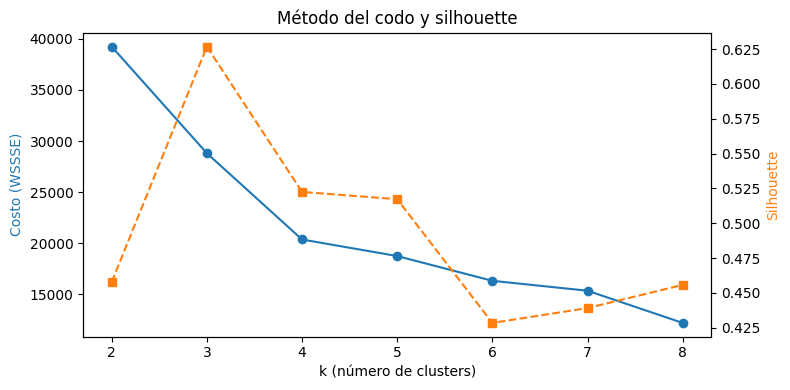

In [0]:
import matplotlib.pyplot as plt

ks = [r[0] for r in resultados]
costos = [r[1] for r in resultados]
sils = [r[2] for r in resultados]

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(ks, costos, "o-", color="tab:blue")
ax1.set_xlabel("k (número de clusters)")
ax1.set_ylabel("Costo (WSSSE)", color="tab:blue")

ax2 = ax1.twinx()
ax2.plot(ks, sils, "s--", color="tab:orange")
ax2.set_ylabel("Silhouette", color="tab:orange")

plt.title("Método del codo y silhouette")
plt.tight_layout()
plt.show()

In [0]:
for k in [3, 4]:
    kmeans = KMeans(featuresCol="features", predictionCol="cluster", k=k, seed=42)
    model_k = Pipeline(stages=[assembler, scaler, kmeans]).fit(df)

    print(f"\n===== k = {k} =====")
    (model_k.transform(df)
     .groupBy("cluster")
     .agg(
         F.count("*").alias("n"),
         *[F.round(F.avg(c), 3).alias(c) for c in FEATURES],
         F.round(F.avg("n_decel_events"), 2).alias("n_decel"),
         F.round(F.avg("speed_q4"), 1).alias("q4_kmh"),
     )
     .orderBy("cluster")
     .display())


===== k = 3 =====


cluster,n,early_speed_ratio,late_speed_ratio,time_to_top_speed_frac,speed_cv,n_decel,q4_kmh
0,2884,0.959,0.981,0.667,0.109,0.61,66.8
1,10834,1.014,0.899,0.19,0.132,0.25,60.1
2,1182,1.111,0.751,0.196,0.208,0.57,46.8



===== k = 4 =====


cluster,n,early_speed_ratio,late_speed_ratio,time_to_top_speed_frac,speed_cv,n_decel,q4_kmh
0,6484,0.989,0.931,0.196,0.119,0.21,63.2
1,515,1.144,0.687,0.206,0.246,0.78,41.8
2,2356,0.96,0.985,0.742,0.108,0.66,66.9
3,5545,1.047,0.856,0.195,0.15,0.32,56.0


### Elección de `k`

| k | Costo (WSSSE) | Reducción | Silhouette | Tamaños |
|---|---|---|---|---|
| 2 | 39.240 | — | 0,458 | 7.643 / 7.257 |
| 3 | 28.817 | −10.423 | **0,627** | 10.834 / 2.884 / 1.182 |
| **4** | **20.378** | **−8.439** | **0,523** | 6.484 / 5.545 / 2.356 / 515 |
| 5 | 18.758 | −1.620 | 0,517 | |
| 6 | 16.337 | −2.421 | 0,428 | |
| 7 | 15.368 | −969 | 0,439 | |
| 8 | 12.219 | −3.149 | 0,456 | |

Se elige **k = 4**:

- **Método del codo:** hasta k = 4 cada cluster adicional reduce el costo en más de 8 mil;
  de k = 4 a k = 5 la reducción cae a 1.620. El codo está en k = 4.
- **Silhouette:** el máximo está en k = 3 (0,627), pero con k = 3 un solo grupo concentra
  el 73% de los caballos y mezcla dos estrategias distintas. Con k = 4 el silhouette (0,523)
  sigue indicando grupos bien separados.
- **Interpretabilidad:** al pasar de k = 3 a k = 4, el grupo mayoritario se divide en dos
  estilos que difieren en ~7 km/h en el último cuarto, y el grupo extremo se depura de 1.182
  a 515 caballos. A partir de k = 6 el silhouette cae por debajo de 0,45 y aparecen grupos
  de menos de 300 caballos que fragmentan estilos en lugar de descubrir nuevos.

### Interpretación de los clusters (k = 4)

| Estilo | n | % | `early_ratio` | `late_ratio` | `time_to_top` | `speed_cv` | Q4 (km/h) |
|---|---|---|---|---|---|---|---|
| Ritmo sostenido | 6.484 | 44% | 0,99 | 0,93 | 0,20 | 0,12 | 63,2 |
| Puntero que se apaga | 5.545 | 37% | 1,05 | 0,86 | 0,20 | 0,15 | 56,0 |
| Cerrador | 2.356 | 16% | 0,96 | 0,99 | 0,74 | 0,11 | 66,9 |
| Se desploma / detenido | 515 | 3% | 1,14 | 0,69 | 0,21 | 0,25 | 41,8 |

- **Ritmo sostenido:** alcanza su máxima velocidad temprano pero administra el esfuerzo:
  arranca en su ritmo promedio y conserva el 93% en el cierre. Es el perfil más regular.
- **Puntero que se apaga:** sale por encima de su ritmo promedio para tomar posición y lo
  paga en el final, donde cae al 86%.
- **Cerrador:** reserva energía y alcanza su máxima velocidad al 74% de la carrera, cerrando
  prácticamente a su ritmo promedio. Registra más frenazos (0,66 por carrera) que el ritmo
  sostenido (0,21), consistente con un caballo que viene desde atrás y debe abrirse paso
  entre el tráfico.
- **Se desploma / detenido:** caída extrema en el último cuarto (42 km/h), el ritmo más
  irregular y la mayor cantidad de frenazos (0,78). Agrupa caballos que se quemaron por
  completo o que se detuvieron durante la carrera.

In [0]:
K = 4
kmeans = KMeans(featuresCol="features", predictionCol="cluster", k=K, seed=42)
model = Pipeline(stages=[assembler, scaler, kmeans]).fit(df)
pred = model.transform(df)

# Nombres según la interpretación (cluster id → estilo)
nombres = {0: "Ritmo sostenido", 1: "Se desploma / detenido",
           2: "Cerrador", 3: "Puntero que se apaga"}
mapping = F.create_map(*[x for k, v in nombres.items() for x in (F.lit(k), F.lit(v))])
pred = pred.withColumn("estilo", mapping[F.col("cluster")])

(pred
 .filter(F.col("is_top3").isNotNull())
 .groupBy("cluster", "estilo")
 .agg(
     F.count("*").alias("n"),
     F.round(F.avg(F.col("is_winner").cast("int")) * 100, 1).alias("pct_gana"),
     F.round(F.avg(F.col("is_top3").cast("int")) * 100, 1).alias("pct_top3"),
     F.round(F.avg("position_at_finish"), 2).alias("posicion_media"),
 )
 .orderBy(F.desc("pct_top3"))
 .display())

cluster,estilo,n,pct_gana,pct_top3,posicion_media
2,Cerrador,2356,16.9,46.9,4.1
0,Ritmo sostenido,6484,15.1,44.8,4.22
3,Puntero que se apaga,5544,10.8,34.6,4.76
1,Se desploma / detenido,515,6.0,15.0,6.51


### ¿Qué estilo gana más?

| Estilo | n | % gana | % top 3 | Posición media |
|---|---|---|---|---|
| Cerrador | 2.356 | 16,9 | 46,9 | 4,10 |
| Ritmo sostenido | 6.484 | 15,1 | 44,8 | 4,22 |
| Puntero que se apaga | 5.544 | 10,8 | 34,6 | 4,76 |
| Se desploma / detenido | 515 | 6,0 | 15,0 | 6,51 |

*Promedio ponderado del dataset: ~13,5% de victorias y ~40% de top 3. Se excluye un caballo
sin resultado en `silver_derby_starts`.*

- El **cerrador** es el estilo más exitoso (46,9% de top 3), seguido muy de cerca por el de
  **ritmo sostenido** (44,8%). Ambos superan el promedio del dataset.
- El **puntero que se apaga** queda 6 puntos por debajo del promedio, y el grupo **se desploma
  / detenido** tiene casi tres veces menos probabilidad de terminar top 3 que el promedio.
- Lo que mejor separa a los estilos exitosos de los demás no es el momento de la velocidad
  máxima (casi idéntico en ritmo sostenido y puntero, ~20% de la carrera), sino **cuánto
  ritmo conservan en el cierre**: `late_speed_ratio` de 0,93 y 0,99 en los dos estilos
  ganadores, frente a 0,86 y 0,69 en los otros dos.

**Precaución:** es una asociación descriptiva, no causal, y la relación puede ir en ambos
sentidos. Un caballo puede perder porque se desplomó, pero también puede desplomarse porque
ya iba perdiendo y el jockey dejó de exigirle en la recta final. El modelo caracteriza el
perfil de carrera, pero no permite distinguir cuál ocurrió primero.

In [0]:
from pyspark.ml.functions import vector_to_array

centers = model.stages[-1].clusterCenters()   # coordenadas estandarizadas de cada centroide
n_feat = len(FEATURES)

scored = pred.withColumn("f", vector_to_array("features"))

# Distancia euclidiana de cada caballo al centroide de SU cluster
dist2 = None
for i in range(n_feat):
    # Mapa cluster -> coordenada i del centroide
    c_i = F.create_map(*[x for k in range(K) for x in (F.lit(k), F.lit(float(centers[k][i])))])
    term = F.pow(F.col("f")[i] - c_i[F.col("cluster")], 2)
    dist2 = term if dist2 is None else dist2 + term

scored = scored.withColumn("anomaly_score", F.sqrt(dist2)).drop("f")

# Distribución del score
scored.select(F.percentile_approx(
    "anomaly_score", [0.5, 0.9, 0.95, 0.98, 0.99, 0.999]
).alias("percentiles")).display()

scored.select("anomaly_score").summary("min", "max").display()

percentiles
"List(0.9047627711568987, 1.562658914720135, 1.7999432983985824, 2.12159253484143, 2.566255128007778, 6.596068058577816)"


summary,anomaly_score
min,0.05037522188873758
max,25.671891451179985


In [0]:
ANOMALY_PCT = 0.99   # top 1% de mayor distancia al centroide

threshold = scored.select(
    F.percentile_approx("anomaly_score", ANOMALY_PCT).alias("t")
).collect()[0]["t"]
print(f"Umbral de anomalía (percentil {ANOMALY_PCT:.0%}): {threshold:.3f}")

scored = scored.withColumn("is_anomaly", F.col("anomaly_score") > threshold)

n_anom = scored.filter("is_anomaly").count()
print(f"Anomalías: {n_anom} de {scored.count()} ({n_anom / scored.count():.2%})")

# ¿De qué estilo salen las anomalías?
(scored
 .groupBy("estilo")
 .agg(
     F.count("*").alias("n"),
     F.sum(F.col("is_anomaly").cast("int")).alias("anomalias"),
 )
 .withColumn("pct_del_estilo", F.round(F.col("anomalias") / F.col("n") * 100, 2))
 .orderBy(F.desc("anomalias"))
 .display())

Umbral de anomalía (percentil 99%): 2.566
Anomalías: 150 de 14900 (1.01%)


estilo,n,anomalias,pct_del_estilo
Se desploma / detenido,515,90,17.48
Cerrador,2356,31,1.32
Puntero que se apaga,5545,27,0.49
Ritmo sostenido,6484,2,0.03


In [0]:
cols_inspeccion = [
    "track_id", "race_date", "race_number", "program_number",
    "estilo", "anomaly_score",
    "n_frames", "race_duration_s",
    "speed_q1", "speed_q2", "speed_q3", "speed_q4",
    "early_speed_ratio", "late_speed_ratio", "time_to_top_speed_frac", "speed_cv",
    "n_decel_events", "max_decel_kmh",
    "position_at_finish", "is_top3",
]

print("=== Las 5 anomalías más extremas ===")
(scored.filter("is_anomaly")
 .orderBy(F.desc("anomaly_score"))
 .select(cols_inspeccion)
 .limit(5)
 .display())

=== Las 5 anomalías más extremas ===


track_id,race_date,race_number,program_number,estilo,anomaly_score,n_frames,race_duration_s,speed_q1,speed_q2,speed_q3,speed_q4,early_speed_ratio,late_speed_ratio,time_to_top_speed_frac,speed_cv,n_decel_events,max_decel_kmh,position_at_finish,is_top3
SAR,2019-08-04,6,10,Se desploma / detenido,25.671891451179985,211,53.75,66.61092592592591,67.04055555555554,6.2904081632653055,0.0,1.9039595962302027,0.0,0.4744186046511628,0.9564978300133327,2,-73.22,11,0
BEL,2019-06-20,2,2,Se desploma / detenido,23.54618610170955,304,75.75,68.32749999999999,62.322368421052595,11.114078947368432,2.0280263157894725,1.9007319601873687,0.05641556378503666,0.14521452145214522,0.8647556722230372,0,-4.34,4,0
BEL,2019-05-24,7,2,Se desploma / detenido,15.048150839224876,322,80.25,69.59753086419751,73.78725000000003,51.093086419753085,0.952125,1.4245005088691927,0.019487796911266456,0.1838006230529595,0.647853785047797,0,-7.710000000000001,9,0
AQU,2019-01-12,7,5,Se desploma / detenido,13.157881139574378,290,72.25,62.72246575342468,71.94694444444445,60.745342465753446,2.417083333333332,1.2681976171800742,0.04887147351492051,0.4809688581314879,0.6018938385037198,0,-4.25,9,0
AQU,2019-02-08,8,4,Se desploma / detenido,12.422741502423907,293,73.0,64.72945945945945,68.13657534246575,42.7978082191781,8.519726027397262,1.405759694935967,0.18502684189280283,0.2191780821917808,0.5855543390756189,4,-46.45,9,0


In [0]:
from pyspark.sql.window import Window

w_estilo = Window.partitionBy("estilo").orderBy(F.desc("anomaly_score"))

print("=== La anomalía más fuerte de los demás estilos ===")
(scored.filter("is_anomaly" ) 
 .filter(F.col("estilo") != "Se desploma / detenido")
 .withColumn("rank", F.row_number().over(w_estilo))
 .filter(F.col("rank") == 1)
 .select(cols_inspeccion)
 .display())

=== La anomalía más fuerte de los demás estilos ===


track_id,race_date,race_number,program_number,estilo,anomaly_score,n_frames,race_duration_s,speed_q1,speed_q2,speed_q3,speed_q4,early_speed_ratio,late_speed_ratio,time_to_top_speed_frac,speed_cv,n_decel_events,max_decel_kmh,position_at_finish,is_top3
AQU,2019-01-12,7,9,Cerrador,5.613824580688316,121,30.0,46.83290322580645,71.998,71.339,68.18200000000002,0.7251025077198403,1.055645406883759,0.475,0.2232361906731999,0,-4.27000000000001,10,0
AQU,2019-03-15,7,5,Puntero que se apaga,4.598490511254145,122,30.25,46.92612903225805,65.87500000000001,60.04741935483871,42.44433333333334,0.8718565826657336,0.7885877692593606,0.34710743801652894,0.2612392091118965,0,-5.659999999999997,7,0
SAR,2019-08-29,10,1,Ritmo sostenido,2.7686544943068814,177,44.0,54.92400000000001,68.85568181818181,64.07613636363637,54.41090909090908,0.9068352161817143,0.8983637118217561,0.2784090909090909,0.20207850495487495,0,-6.079999999999998,9,0


In [0]:
casos = [
    ("SAR", "2019-08-04", 6),   # caso 1: ¿se detuvo de verdad?
    ("BEL", "2019-06-20", 2),   # caso 2: ¿cómo llegó 4° si se detuvo?
    ("AQU", "2019-01-12", 7),   # dos anomalías en la misma carrera
]

for track, fecha, carrera in casos:
    print(f"\n=== {track} {fecha} carrera {carrera} ===")
    (scored
     .filter((F.col("track_id") == track) &
             (F.col("race_date") == fecha) &
             (F.col("race_number") == carrera))
     .select("program_number", "estilo", "n_frames", "race_duration_s",
             "speed_q3", "speed_q4", "position_at_finish", "is_anomaly")
     .orderBy("position_at_finish")
     .show(truncate=False))


=== SAR 2019-08-04 carrera 6 ===
+--------------+----------------------+--------+---------------+------------------+------------------+------------------+----------+
|program_number|estilo                |n_frames|race_duration_s|speed_q3          |speed_q4          |position_at_finish|is_anomaly|
+--------------+----------------------+--------+---------------+------------------+------------------+------------------+----------+
|8             |Ritmo sostenido       |275     |69.25          |72.5539705882353  |63.43101449275362 |1                 |false     |
|2             |Ritmo sostenido       |283     |70.5           |72.63338028169015 |62.409142857142825|2                 |false     |
|4             |Ritmo sostenido       |282     |70.5           |72.06225352112679 |64.288            |3                 |false     |
|12            |Ritmo sostenido       |282     |70.5           |71.58802816901407 |64.46528571428573 |4                 |false     |
|11            |Cerrador           

### Detección de anomalías

**Score:** distancia euclidiana de cada caballo-carrera al centroide de su cluster, en el
espacio estandarizado. **Umbral:** percentil 99 (score > 2,57), es decir, el 1% más alejado
(150 caballos). Se eligió el 1% porque la distribución crece de forma gradual hasta el
percentil 99 y luego da un salto (2,57 en el p99, 6,60 en el p99,9, 25,7 en el máximo):
el umbral separa la variación normal de la cola de casos extremos.

| Estilo | n | Anomalías | % del estilo |
|---|---|---|---|
| Se desploma / detenido | 515 | 90 | 17,5% |
| Cerrador | 2.356 | 31 | 1,3% |
| Puntero que se apaga | 5.545 | 27 | 0,5% |
| Ritmo sostenido | 6.484 | 2 | 0,03% |

El 60% de las anomalías sale del cluster más pequeño. Ese cluster agrupa casos extremos de
naturaleza distinta, por lo que es muy disperso y sus miembros quedan lejos de su centroide.
**Limitación:** la distancia al centroide penaliza a los clusters dispersos; una alternativa
sería normalizar el score por la distancia media de cada cluster.

### Inspección manual

Cada anomalía se comparó con los demás caballos de su misma carrera (duración del registro,
velocidades por cuarto y posición final):

| Caballo | Score | Observación | Diagnóstico |
|---|---|---|---|
| SAR 2019-08-04 c6 #10 | 25,7 | Registro de 54 s frente a 70,5 s del resto; Q3 = 6,3 y Q4 = 0 km/h; llegó último (11/11) | **Incidente real**: se detuvo a mitad de carrera |
| BEL 2019-06-20 c2 #2 | 23,5 | Registro 6 s más corto que el resto; Q4 = 2 km/h; llegó último (4/4) | **Incidente real** |
| AQU 2019-01-12 c7 #5 | 13,2 | Registro de 72 s frente a 96 s del resto; Q4 = 2,4 km/h; llegó 9° | **Incidente real** |
| AQU 2019-01-12 c7 #9 | 5,6 | Registro de solo 30 s frente a 96 s del resto, terminando a 68 km/h | **Falla de datos**: tracking cortado |

**Cómo se distinguen:** un caballo que se detiene muestra una velocidad que **baja hasta 0**
y un registro que termina antes que el de sus rivales, con una posición final al fondo.
Un registro que **se corta a velocidad de carrera** (#9) indica una falla del GPS, no del
caballo: su perfil describe solo una parte de la carrera.

**Hallazgo adicional (efecto de carrera):** en BEL 2019-06-20 c2, los tres primeros lugares
(incluido el ganador) también cayeron en el cluster "Se desploma", con Q4 de 41–48 km/h y
registros idénticos de 81,5 s. Un ganador no se desploma en el cierre: lo más probable es
que el tracking de esa carrera continúe después de la meta e incluya la desaceleración
posterior (*gallop out*). Las features asumen que el registro empieza y termina con la
carrera; se recortó la espera en el partidor, pero no el exceso al final. Una mejora sería
recortar cada registro en el cruce de la meta o comparar a cada caballo contra los demás
caballos de su carrera.

## Registro en MLflow

Se sigue la convención del clasificador top-3: registro manual de parámetros, métricas y
modelo dentro de `mlflow.start_run()` (el autolog de Spark no funciona en cómputo serverless).
Además de las métricas del modelo final, se loguea la curva completa de costo y silhouette
para k = 2..8 y la gráfica del codo, de modo que la elección de `k` quede documentada en el run.

In [0]:
import mlflow.spark
from mlflow.models.signature import infer_signature

mlflow.set_registry_uri("databricks-uc")

# Sin depender de model.summary (se pierde en serverless)
cost_final = scored.agg(F.sum(F.pow("anomaly_score", 2))).first()[0]
sizes = [r["count"] for r in pred.groupBy("cluster").count().orderBy("cluster").collect()]
silhouette_final = evaluator.evaluate(pred)
n_total = scored.count()

with mlflow.start_run(run_name=f"{USER_INITIALS}_kmeans_race_profiles") as run:

    # --- Parámetros: modelo + decisiones de la tabla Gold ---
    mlflow.log_params({
        "student": USER_INITIALS,
        "algorithm": "KMeans",
        "k": K,
        "seed": 42,
        "features": ",".join(FEATURES),
        "scaler": "StandardScaler(withMean=True, withStd=True)",
        "anomaly_score": "distancia euclidiana al centroide (espacio estandarizado)",
        "anomaly_percentile": ANOMALY_PCT,
        "anomaly_threshold": round(threshold, 4),
        "gold_min_frames": 100,
        "gold_max_speed_kmh": 90,
        "gold_decel_kmh": -12,
    })

    # --- Métricas del modelo final ---
    mlflow.log_metrics({
        "silhouette": silhouette_final,
        "training_cost": cost_final,
        "n_anomalies": n_anom,
        "pct_anomalies": n_anom / n_total * 100,
        **{f"size_cluster_{i}": s for i, s in enumerate(sizes)},
    })

    # --- Curva del codo: una métrica por k (MLflow la grafica con step = k) ---
    for k_i, costo_i, sil_i in resultados:
        mlflow.log_metric("elbow_cost", costo_i, step=k_i)
        mlflow.log_metric("elbow_silhouette", sil_i, step=k_i)

    mlflow.log_figure(fig, "elbow_silhouette.png")

    # --- Modelo ---
    sample_input = df.select(*FEATURES).limit(5).toPandas()
    sample_output = pred.select("cluster").limit(5).toPandas()
    signature = infer_signature(sample_input, sample_output)

    mlflow.spark.log_model(
        model,
        artifact_path="model",
        signature=signature,
        dfs_tmpdir=MLFLOW_DFS_TMPDIR,
    )

    run_id = run.info.run_id

print(f"Run: {run_id}")
print(f"Silhouette: {silhouette_final:.4f} | Costo: {cost_final:,.0f}")
print(f"Anomalías: {n_anom} ({n_anom / n_total:.2%})")

/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/17 17:01:52 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /local_disk0/user_tmp_data/spark-367afe5d-2ad9-4f28-a483-b9/tmp8s5a3m59/model, flavor: spark). Fall back to r

Run: fe76df9df330418aac9e58f2c2d7ad29
Silhouette: 0.5225 | Costo: 20,362
Anomalías: 150 (1.01%)


## Tabla de salida: `gold_derby_race_profiles`

Una fila por caballo-carrera con su cluster, estilo, score de anomalía y bandera de anomalía.
Incluye `start_id` para unirla con `gold_derby_race_dynamics` y `gold_derby_ml_features`.

In [0]:
race_profiles = (
    scored
    .select(
        "start_id",
        *START_KEYS,
        "cluster", "estilo",
        "anomaly_score", "is_anomaly",
    )
    .withColumn("model_run_id", F.lit(run_id))
    .withColumn("_created_at", F.current_timestamp())
)

# Validación pre-escritura
n_rows = race_profiles.count()
n_pk = race_profiles.select("start_id").distinct().count()
assert n_rows == n_pk, "start_id duplicado"
assert race_profiles.filter(F.col("cluster").isNull()).count() == 0, "Hay caballos sin cluster"

(race_profiles.write
 .format("delta")
 .mode("overwrite")
 .option("overwriteSchema", "true")
 .saveAsTable(T_GOLD_RACE_PROFILES))

print(f"Escritas {spark.table(T_GOLD_RACE_PROFILES).count():,} filas en {T_GOLD_RACE_PROFILES}")

Escritas 14,900 filas en `51810_databricks`.`sebastian_velasco`.gold_derby_race_profiles


## Respuestas a las preguntas

### 1. ¿Por qué este modelo sí puede usar las features de velocidad GPS, cuando el clasificador top-3 las prohíbe?

La diferencia está en el **momento de la predicción**. El clasificador top-3 se usa **antes
de la largada**, para estimar quién terminará entre los tres primeros. En ese momento la
carrera no se ha corrido y el tracking GPS no existe: entrenar con esas columnas daría un
modelo con métricas excelentes en validación pero inútil en producción, porque dependería
de información del futuro (*data leakage*).

Este modelo se usa **después de la carrera** y su objetivo no es predecir el resultado sino
**describir cómo corrió cada caballo**. En ese momento el tracking completo ya está
disponible, y es precisamente el fenómeno que se quiere caracterizar. Además, el resultado
(`is_top3`, `position_at_finish`) **no entra al modelo**: solo se usa después para
interpretar los clusters. El modelo no aprende de la variable que luego se analiza.

### 2. ¿Por qué estandarizar antes de KMeans?

Respondida en la sección *¿Por qué estandarizar antes de KMeans?*: KMeans usa distancia
euclidiana, y sin escalar las features con mayor dispersión numérica dominan la distancia
(`time_to_top_speed_frac` pesaría 3,5 veces más que `speed_cv`). Con `speed_q1..q4` en km/h,
cuya desviación es 40 a 150 veces la de los ratios, el modelo agruparía por velocidad
absoluta y los ratios de forma serían prácticamente invisibles.

### 3. ¿Por qué usar ratios de forma en vez de velocidades absolutas para agrupar estilos?

Un **estilo** de carrera describe **cómo se distribuye el esfuerzo**, no qué tan rápido es
el caballo. La velocidad absoluta mezcla el estilo con factores ajenos a él: la calidad del
caballo, la distancia de la carrera, la superficie y el estado de la pista. Dos caballos con
la misma estrategia, uno en una pista rápida a 72 km/h y otro en una pista pesada a 64 km/h,
quedarían en grupos distintos si se usaran velocidades absolutas.

Los ratios **dividen por el promedio del propio caballo**, lo que elimina el nivel de
velocidad y conserva solo la forma del perfil: `late_speed_ratio = 0,86` significa
"terminó al 86% de su propio ritmo", sea un caballo de 60 o de 70 km/h. Los resultados lo
confirman: los clusters "Ritmo sostenido" y "Puntero que se apaga" alcanzan su máximo en el
mismo momento (~20% de la carrera) y se diferencian por cuánto ritmo conservan al final
(0,93 frente a 0,86), algo que la velocidad absoluta no habría aislado.

### 4. ¿Una anomalía detectada es necesariamente un incidente de carrera?

**No.** El score mide qué tan lejos está un perfil del de su grupo, no la causa. La
inspección manual encontró al menos cuatro orígenes distintos:

| Causa | Ejemplo | Cómo se distingue |
|---|---|---|
| **Incidente real** | SAR 2019-08-04 c6 #10 | La velocidad baja hasta 0, el registro termina antes que el de sus rivales y el caballo llega último |
| **Registro cortado** | AQU 2019-01-12 c7 #9 | El registro (30 s) es mucho más corto que el de sus rivales (96 s) y termina **a velocidad de carrera** (68 km/h): falló el GPS, no el caballo |
| **Ruido GPS** | Picos de −73 y −46 km/h en `max_decel_kmh` | Caídas imposibles en 0,25 s, acompañadas de una subida igual de brusca en el frame anterior (patrón ida y vuelta) |
| **Efecto de la carrera** | BEL 2019-06-20 c2 | Todos los caballos de la carrera, incluido el ganador, muestran el mismo colapso en Q4: el registro probablemente incluye la desaceleración después de la meta |

**Criterios para distinguirlas:**
1. **Comparar contra los rivales de la misma carrera:** si solo un caballo tiene un registro
   corto o un perfil extraño, el problema es suyo; si todos lo tienen, es un efecto de la
   carrera o del registro.
2. **Mirar cómo termina el registro:** velocidad que desciende hasta 0 indica un caballo
   detenido; un registro que se corta a velocidad alta indica una falla de tracking.
3. **Verificar la coherencia con el resultado:** un caballo que "se detuvo" debería llegar
   al fondo del campo.
4. **Revisar el patrón de los frenazos:** una caída imposible precedida de una subida igual
   de brusca es ruido GPS, no una desaceleración real.

Por eso el score de anomalía es un **filtro para priorizar la revisión**, no un diagnóstico:
reduce 14.900 carreras a 150 candidatas, pero cada una requiere inspección para determinar
si se trata de un incidente o de un problema de datos.